# LAB 04 — Data Preparation & Preprocessing Pipelines

**Module:** Data Preparation & Preprocessing Pipelines
**Session:** 04
**Duration:** 150 minutes (10-minute break included)
**Audience:** Başlangıç seviyesi Python / Machine Learning katılımcıları (LAB02 ve LAB03'ü tamamlamış
olmalı)

## LAB02 ve LAB03'ten Devam

Bu LAB, **LAB02 — Python for Machine Learning & Data Manipulation** ve
**LAB03 — Statistics & Exploratory Data Analysis**'ın devamıdır.

- **LAB02**'de NumPy, Pandas (`Series`/`DataFrame`), data loading, filtering/sorting ve
  groupby/aggregation öğrendiniz.
- **LAB03**'te descriptive statistics, variance/std, IQR, outlier analizi, data quality assessment ve
  correlation analizi ile bu dataset'i istatistiksel olarak incelediniz.

Bu LAB'da bu bilgiler **sıfırdan tekrar öğretilmeyecek** — LAB03'te tespit ettiğimiz veri kalitesi ve
veri yapısı sorunlarının, bir Machine Learning modeline veri vermeden önce **nasıl ele alınacağını**
öğreneceğiz.

## Bu LAB'ın Ana Hedefi

LAB03'te tespit edilen veri kalitesi ve veri yapısı sorunlarının, Machine Learning modelleme sürecine
uygun, **tekrar üretilebilir (reproducible)** ve **veri sızıntısından (data leakage) arındırılmış**
bir şekilde nasıl ele alınacağını öğretmek.

## Bu LAB'ın Sonunda Yapabilecekleriniz

1. Data Quality kontrolleri gerçekleştirmek.
2. Missing Values için uygun yöntemler seçmek.
3. Duplicate ve Outlier kayıtlarını değerlendirmek.
4. Categorical Encoding uygulamak.
5. Feature Scaling yöntemlerini kullanmak.
6. Train, Validation ve Test veri kümeleri oluşturmak.
7. Data Leakage risklerini belirlemek.
8. Scikit-learn `Pipeline` ve `ColumnTransformer` kullanmak.
9. Tekrar kullanılabilir bir preprocessing workflow geliştirmek.
10. Preprocessing işlemlerinin yalnızca training verisinden öğrenildiğini doğrulamak.

## Kullanılan Veri Kümesi

Bu LAB'da, LAB02 ve LAB03'te kullandığınız **aynı** E-Commerce Shipping veri kümesi kullanılır:
`data/ecommerce_shipping/Train.csv`. Northwind veri kümesi bu LAB'da **kullanılmaz**.

> **Önemli bir sınırlama:** Bu veri kümesi preprocessing tekniklerini öğretmek için kullanılmaktadır.
> Gerçek bir operasyonel tahmin sisteminde, bir feature'ın tahmin anında (prediction time) gerçekten
> erişilebilir olması gerekir. Örneğin `Customer_rating`, `Customer_care_calls` ve `Discount_offered`
> gibi alanların, bir gönderi henüz teslim edilmeden **önce** gerçekten bilinip bilinmediği bu dataset
> içinde doğrulanmamıştır. Bu LAB boyunca bu değişkenleri preprocessing örnekleri için kullanacağız,
> ancak bunları gerçek zamanlı bir tahmin sistemi için "kesinlikle uygun" feature'lar olarak
> **sunmuyoruz** — bu, ayrıca doğrulanması gereken bir varsayımdır.

> **Bu LAB'da model eğitimi yapılmaz.** Amaç yalnızca, bir sonraki LAB'larda (LAB05, LAB06) model
> eğitimiyle birlikte kullanılacak, leakage'dan arındırılmış bir preprocessing pipeline'ı inşa etmektir.


---
## Section 1 — LAB03 Review & Preprocessing Workflow
**Süre: 10 dakika**

### Learning Objective

EDA (LAB03) ile Data Preparation (LAB04) arasındaki farkı anlamak; dataset'i hızlıca hatırlamak ve
preprocessing workflow'una giriş yapmak.

### Concept Explanation

- **EDA vs Data Preparation**: EDA (LAB03), veriyi **gözlemler ve raporlar** — veriyi değiştirmez.
  Data Preparation (bu LAB), veri kalitesi sorunlarını modele uygun hâle getirmek için veriyi **gerçekten
  dönüştürür** (impute eder, encode eder, scale eder).
- **Data Quality Findings**: LAB03'te bu dataset'te eksik değer ve duplicate bulunmadığını, ancak
  `Discount_offered` gibi bazı değişkenlerin çarpık dağıldığını gözlemlemiştik.
- **Raw Data vs Model-Ready Data**: Ham veri (raw data), insan tarafından okunabilir ama bir Scikit-learn
  modeline doğrudan verilemez (örn. metin kategoriler). Model-ready veri, tamamen sayısal ve tutarlı
  bir formattadır.
- **Preprocessing Workflow**: Veri kalitesi kontrolü → eksik/duplicate/outlier değerlendirmesi →
  encoding → scaling → train/validation/test ayrımı → tek bir pipeline içinde birleştirme.
- **Training Data vs Unseen Data**: "Unseen data", modelin (veya preprocessing adımının) daha önce
  görmediği veridir — validation, test verisi veya gerçek dünyada gelecekte karşılaşılacak veridir.
- **Reproducible Transformations**: Aynı kodun, aynı `random_state` ile her çalıştırıldığında aynı
  sonucu üretmesidir.

### Hands-On


In [1]:
# Same environment setup pattern as LAB02/LAB03: resolve the project root, add src/ to
# sys.path, then load the shared configuration and the dataset.
import sys
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print("Project root:", PROJECT_ROOT)


Project root: /app


In [2]:
from data_loading import load_config, load_ecommerce_shipping

config = load_config()
RANDOM_STATE = config["random_seed"]

df = load_ecommerce_shipping(config)
print("Dataset shape:", df.shape)
print("Random state (from config/settings.yaml):", RANDOM_STATE)


Dataset shape: (10999, 12)
Random state (from config/settings.yaml): 42


In [3]:
print("Columns:", df.columns.tolist())
df.dtypes


Columns: ['ID', 'Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N']


ID                     int64
Warehouse_block          str
Mode_of_Shipment         str
Customer_care_calls    int64
Customer_rating        int64
Cost_of_the_Product    int64
Prior_purchases        int64
Product_importance       str
Gender                   str
Discount_offered       int64
Weight_in_gms          int64
Reached.on.Time_Y.N    int64
dtype: object

In [4]:
numerical_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = df.select_dtypes(include="string").columns.tolist()

print("Numerical columns  :", numerical_columns)
print("Categorical columns:", categorical_columns)


Numerical columns  : ['ID', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N']
Categorical columns: ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']


In [5]:
missing_summary = df.isna().sum()
print("Missing value summary (count per column):")
print(missing_summary)
print()
print("Total missing values in the real dataset:", missing_summary.sum())


Missing value summary (count per column):
ID                     0
Warehouse_block        0
Mode_of_Shipment       0
Customer_care_calls    0
Customer_rating        0
Cost_of_the_Product    0
Prior_purchases        0
Product_importance     0
Gender                 0
Discount_offered       0
Weight_in_gms          0
Reached.on.Time_Y.N    0
dtype: int64

Total missing values in the real dataset: 0


In [6]:
target_counts = df["Reached.on.Time_Y.N"].value_counts().sort_index()
target_pct = (df["Reached.on.Time_Y.N"].value_counts(normalize=True).sort_index() * 100).round(2)

print("Target value counts (0 = Reached On Time, 1 = Not Reached On Time):")
print(target_counts)
print()
print("Target distribution (%):")
print(target_pct)


Target value counts (0 = Reached On Time, 1 = Not Reached On Time):
Reached.on.Time_Y.N
0    4436
1    6563
Name: count, dtype: int64

Target distribution (%):
Reached.on.Time_Y.N
0    40.33
1    59.67
Name: proportion, dtype: float64


### Educational Question

**"LAB03'te veri kalitesi sorunlarını belirledik. Bu sorunları neden doğrudan bütün dataset üzerinde
çözmemeliyiz?"**

**Beklenen yanıt:** Bazı preprocessing işlemleri (örn. `SimpleImputer`'ın öğrendiği ortalama/medyan,
`StandardScaler`'ın öğrendiği mean/std, `OneHotEncoder`'ın öğrendiği kategori listesi) veriden
**parametre öğrenir**. Bu parametrelerin validation veya test verisinden (kısmen veya tamamen)
öğrenilmesi, modelin değerlendirme aşamasında "unseen" olması gereken bilgiye dolaylı olarak erişmesine
yol açar — buna **Data Leakage** denir. Leakage, değerlendirme sonuçlarının gerçekte olduğundan daha
iyimser görünmesine neden olabilir.

### Important

Bu LAB boyunca öğrenilen her preprocessing işlemi **yalnızca doğru veri bölmesi (training set) üzerinde**
gerçekleştirilmelidir. Bu kuralı aklınızda tutarak ilerleyin — Section 6 ve Section 7'de bunu somut
kod ile uygulayacağız.

### Student Exercise


In [7]:
# Student Exercise:
# TODO: Using numerical_columns and categorical_columns, confirm that together they cover every
#       column in df except "ID" (an identifier, not a feature) and "Reached.on.Time_Y.N" (the target).
# TODO: Print the ratio between the two target classes (e.g. how many times more "Late" than "On Time").

# all_feature_columns = set(numerical_columns) | set(categorical_columns)
# print(all_feature_columns - {"ID", "Reached.on.Time_Y.N"} == set(df.columns) - {"ID", "Reached.on.Time_Y.N"})


---
## Section 2 — Data Quality & Validation
**Süre: 15 dakika**

### Learning Objective

Bir dataset'in modele verilmeden önce karşılaması gereken temel veri kalitesi boyutlarını sistematik
olarak kontrol etmek.

### Concept Explanation

- **Completeness**: Beklenen değerlerin ne kadarının gerçekten mevcut (eksik olmayan) olduğu.
- **Accuracy**: Değerlerin gerçek dünyadaki doğru değeri ne kadar yansıttığı (örn. yanlışlıkla negatif
  yazılmış bir ağırlık).
- **Consistency**: Aynı bilginin farklı yerlerde çelişmeden tutarlı şekilde temsil edilmesi.
- **Uniqueness**: Her gözlemin (örn. her `ID`) tekil olması, tekrarlanmaması.
- **Validity**: Değerlerin, tanımlı kurallara (veri tipi, aralık, kategori listesi) uyması.
- **Data Type Validation**: Bir sütunun beklenen veri tipinde (`int64`, `string` vb.) olup olmadığının
  kontrolü.
- **Range Validation**: Sayısal bir sütunun değerlerinin mantıklı bir aralıkta olup olmadığının kontrolü.
- **Categorical Validation**: Kategorik bir sütunun beklenmedik yazım farklılıkları içermediğinin
  kontrolü.
- **Target Validation**: Hedef değişkenin, beklenen (burada: `{0, 1}`) değerler dışında bir şey
  içermediğinin kontrolü.

### Hands-On


In [8]:
# 1. Null value counts.
df.isna().sum()

ID                     0
Warehouse_block        0
Mode_of_Shipment       0
Customer_care_calls    0
Customer_rating        0
Cost_of_the_Product    0
Prior_purchases        0
Product_importance     0
Gender                 0
Discount_offered       0
Weight_in_gms          0
Reached.on.Time_Y.N    0
dtype: int64

In [9]:
# 2 & 3. Duplicate records and duplicate IDs.
print("Duplicate row count:", df.duplicated().sum())
print("Duplicate ID count :", df["ID"].duplicated().sum())


Duplicate row count: 0
Duplicate ID count : 0


In [10]:
# 4. Expected column validation.
expected_columns = [
    "ID",
    "Warehouse_block",
    "Mode_of_Shipment",
    "Customer_care_calls",
    "Customer_rating",
    "Cost_of_the_Product",
    "Prior_purchases",
    "Product_importance",
    "Gender",
    "Discount_offered",
    "Weight_in_gms",
    "Reached.on.Time_Y.N",
]

assert list(df.columns) == expected_columns, "Dataset columns do not match the expected schema."
print("All expected columns are present, in the expected order.")


All expected columns are present, in the expected order.


In [11]:
# 5. Numerical range checks.
df[numerical_columns].agg(["min", "max"]).T


,min,max
ID,1,10999
Customer_care_calls,2,7
Customer_rating,1,5
Cost_of_the_Product,96,310
Prior_purchases,2,10
Discount_offered,1,65
Weight_in_gms,1001,7846
Reached.on.Time_Y.N,0,1


In [12]:
# 6. Categorical value inspection.
for col in categorical_columns:
    print(f"{col}: {sorted(df[col].unique())}")


Warehouse_block: ['A', 'B', 'C', 'D', 'F']
Mode_of_Shipment: ['Flight', 'Road', 'Ship']
Product_importance: ['high', 'low', 'medium']
Gender: ['F', 'M']


In [13]:
# 7 & 8. Target distribution and invalid target values.
unique_target_values = sorted(df["Reached.on.Time_Y.N"].unique())
assert unique_target_values == [0, 1], f"Unexpected target values: {unique_target_values}"
print("Target column only contains the expected values:", unique_target_values)


Target column only contains the expected values: [np.int64(0), np.int64(1)]


### Data Quality Summary


In [14]:
data_quality_summary = pd.DataFrame(
    {
        "Column": df.columns,
        "Data_Type": df.dtypes.astype(str).values,
        "Missing_Count": df.isna().sum().values,
        "Missing_Rate": (df.isna().mean() * 100).round(3).values,
        "Unique_Count": [df[col].nunique() for col in df.columns],
    }
)
data_quality_summary


,Column,Data_Type,Missing_Count,Missing_Rate,Unique_Count
0,ID,int64,0,0.0,10999
1,Warehouse_block,str,0,0.0,5
2,Mode_of_Shipment,str,0,0.0,3
3,Customer_care_calls,int64,0,0.0,6
4,Customer_rating,int64,0,0.0,5
5,Cost_of_the_Product,int64,0,0.0,215
6,Prior_purchases,int64,0,0.0,8
7,Product_importance,str,0,0.0,3
8,Gender,str,0,0.0,2
9,Discount_offered,int64,0,0.0,65


### Technical Rules

- Yukarıdaki tüm kontroller yalnızca Pandas `dtype` bilgisine dayanır — ancak **dtype, her zaman
  değişkenin gerçek anlamını (semantiğini) yansıtmaz**. Örneğin `Customer_rating`, Pandas tarafından
  sayısal (`int64`) olarak saklanır, ancak semantik olarak **ordinal** bir değişkendir (1-5 arası bir
  sıralı puan) — bir "2.5 ortalama rating" aradaki aralıkların eşit olduğunu varsayar, bu her zaman
  doğru olmayabilir.
- Bu bölümdeki kontroller **tamamen salt okunur**dur — `df` üzerinde hiçbir değişiklik yapılmamıştır ve
  orijinal CSV dosyası hiçbir şekilde değiştirilmemiştir.

### Student Exercise


In [15]:
# Student Exercise:
# TODO: "Discount_offered" sütununun gerçek min/max değerlerini inceleyin (yukarıdaki range check
#       tablosundan). Bu değerlerin bir yüzde indirim (%0-100) olarak makul olup olmadığını bir
#       yorum satırında tartışın.

# print(df["Discount_offered"].min(), df["Discount_offered"].max())


---
## Section 3 — Missing Values & Duplicate Handling
**Süre: 20 dakika**

### Learning Objective

Eksik değer mekanizmalarını ve imputation stratejilerini anlamak; `SimpleImputer` kullanmak; duplicate
kayıtları tespit etmek.

### Concept Explanation

- **Missing Completely at Random (MCAR)**: Bir değerin eksik olma olasılığı, hiçbir değişkenle
  ilişkili değildir (tamamen şans eseri).
- **Missing at Random (MAR)**: Bir değerin eksik olma olasılığı, **gözlemlenen başka bir değişkenle**
  ilişkilidir (örn. belirli bir depo bloğundaki kayıtlarda daha sık eksik veri olması).
- **Missing Not at Random (MNAR)**: Bir değerin eksik olma olasılığı, **değerin kendisiyle** ilişkilidir
  (örn. çok yüksek maliyetli ürünlerin maliyetinin bilinçli olarak gizlenmesi).
- **Mean / Median / Most Frequent / Constant Imputation**: Eksik bir değeri sırasıyla ortalama, medyan,
  en sık görülen değer veya sabit bir değerle doldurma stratejileridir.
- **Missing Indicators**: Bir değerin orijinal olarak eksik olup olmadığını ayrı bir binary sütunda
  saklamaktır (bilginin kendisini kaybetmemek için).
- **Duplicate Detection / Data Integrity**: Birden fazla satırın (veya tekil olması gereken bir anahtarın)
  tekrarlanıp tekrarlanmadığının kontrolüdür.

### Hands-On — Missing Values

LAB03'te gördüğümüz gibi, bu **gerçek dataset'te eksik değer bulunmamaktadır**
(`df.isna().sum().sum() == 0`). Bu, imputation tekniklerini öğretmek için yeterli değildir — bu nedenle
aşağıda, dataset'in **bellekteki bir kopyasında**, yalnızca öğretim amacıyla, kontrollü şekilde eksik
değerler üreteceğiz.


In [16]:
# IMPORTANT: this synthetic missing-value injection happens on an in-memory COPY only.
# The original "df" and the original CSV file are never modified.
rng = np.random.default_rng(seed=RANDOM_STATE)

demo_df = df.copy()
n_missing = int(len(demo_df) * 0.05)
missing_positions = rng.choice(demo_df.index, size=n_missing, replace=False)
demo_df.loc[missing_positions, "Weight_in_gms"] = np.nan

print("[SYNTHETIC] Missing values injected into demo_df['Weight_in_gms']:", demo_df["Weight_in_gms"].isna().sum())
print(f"[SYNTHETIC] Missing rate: {demo_df['Weight_in_gms'].isna().mean() * 100:.2f}%")
print()
print("Original df is untouched -> total missing values:", df.isna().sum().sum())


[SYNTHETIC] Missing values injected into demo_df['Weight_in_gms']: 549
[SYNTHETIC] Missing rate: 4.99%

Original df is untouched -> total missing values: 0


> Yukarıdaki eksik değerler **gerçek bir veri kalitesi sorunu değildir** — yalnızca `SimpleImputer`
> stratejilerini gösterebilmek için `demo_df` adlı bir kopyada, sabit bir `random_state` ile üretilmiştir.
> Bu LAB'ın hiçbir yerinde bu durum gerçek bir dataset bulgusu olarak raporlanmamaktadır.

### SimpleImputer Strategies


In [17]:
from sklearn.impute import SimpleImputer

strategies = ["mean", "median", "most_frequent", "constant"]
strategy_results = {}

for strategy in strategies:
    kwargs = {"strategy": strategy}
    if strategy == "constant":
        kwargs["fill_value"] = 0

    imputer = SimpleImputer(**kwargs)
    imputed_values = imputer.fit_transform(demo_df[["Weight_in_gms"]])
    strategy_results[strategy] = imputed_values[missing_positions[:5].argsort()][:5].ravel()

pd.DataFrame(strategy_results, index=[f"row_{i}" for i in range(5)])


,mean,median,most_frequent,constant
row_0,1177.0,1177.0,1177.0,1177.0
row_1,3374.0,3374.0,3374.0,3374.0
row_2,1233.0,1233.0,1233.0,1233.0
row_3,3088.0,3088.0,3088.0,3088.0
row_4,2484.0,2484.0,2484.0,2484.0


Yukarıdaki tablo, aynı 5 eksik satırın her stratejiye göre **farklı** bir değerle doldurulduğunu gösterir
— `mean` ve `median` genellikle birbirine yakın ama aynı değildir (LAB03'te gördüğümüz gibi,
`Weight_in_gms` hafifçe çarpık bir dağılıma sahiptir); `constant` ise tamamen keyfi bir değer
(burada `0`) atar ve dikkatli kullanılmadığı takdirde yanıltıcı olabilir.

### Critical Leakage Rule

`SimpleImputer`, **training verisine `fit` edilmelidir**. Validation ve test verilerinde yalnızca
`transform` uygulanmalıdır — `fit` tekrar çağrılmamalıdır.


In [18]:
# Illustrative split, local to this section only (the official train/val/test split comes in Section 6).
demo_train = demo_df.iloc[: int(len(demo_df) * 0.8)]
demo_unseen = demo_df.iloc[int(len(demo_df) * 0.8) :]

imputer = SimpleImputer(strategy="median")

# fit_transform() on training data: LEARNS the median AND applies it in one step.
demo_train_imputed = imputer.fit_transform(demo_train[["Weight_in_gms"]])
print("Learned median (from demo_train only):", imputer.statistics_[0])

# transform() on unseen data: REUSES the already-learned median, learns nothing new.
demo_unseen_imputed = imputer.transform(demo_unseen[["Weight_in_gms"]])
print("Same imputer re-applied to demo_unseen -> no new statistics learned.")


Learned median (from demo_train only): 4048.5
Same imputer re-applied to demo_unseen -> no new statistics learned.


### Duplicate Handling

Gerçek dataset'te duplicate satır veya duplicate `ID` bulunmamaktadır. Bu teknikleri gösterebilmek için,
başka bir **bellekteki kopya**da, bilinçli olarak birkaç duplicate satır ekleyeceğiz.


In [19]:
# IMPORTANT: synthetic duplicates, in-memory only — not a real dataset finding.
demo_df_with_dupes = pd.concat([df, df.sample(n=5, random_state=RANDOM_STATE)], ignore_index=True)

print("[SYNTHETIC] Row count after adding 5 duplicated rows:", len(demo_df_with_dupes))
print("[SYNTHETIC] duplicated() count:", demo_df_with_dupes.duplicated().sum())
print("[SYNTHETIC] duplicated ID count:", demo_df_with_dupes["ID"].duplicated().sum())


[SYNTHETIC] Row count after adding 5 duplicated rows: 11004
[SYNTHETIC] duplicated() count: 5
[SYNTHETIC] duplicated ID count: 5


In [20]:
# drop_duplicates() removes full-row duplicates, keeping the first occurrence by default.
demo_df_deduplicated = demo_df_with_dupes.drop_duplicates()
print("Row count after drop_duplicates():", len(demo_df_deduplicated))
print("Matches original row count:", len(demo_df_deduplicated) == len(df))


Row count after drop_duplicates(): 10999
Matches original row count: True


**Hangi kayıt silinmeli?** `drop_duplicates()`, varsayılan olarak **ilk görülen** satırı tutar ve
sonraki aynı satırları siler. Gerçek bir projede hangi kaydın "doğru" kabul edileceği (ilk mi, son mu,
yoksa en güncel zaman damgalı kayıt mı) **domain context**'e bağlıdır — bu LAB'da tüm duplicate'ler
yapay olarak eklendiği için bu karar basittir, ancak gerçek bir dataset'te dikkatle değerlendirilmelidir.

> Duplicate kayıtlar **otomatik olarak** silinmemelidir — önce neden oluştukları (örn. bir veri
> aktarım hatası mı, yoksa gerçekten tekrarlanan bir işlem mi) anlaşılmalıdır.

### Student Exercise

Bir numerical feature içindeki eksik değerleri median ile dolduran bir örnek geliştirin. İşlem sonunda
eksik değerlerin durumunu kontrol edin.


In [21]:
# Student Exercise:
# TODO: Pick a numerical column from demo_df (other than "Weight_in_gms") and artificially set a few
#       values to NaN (reuse the same rng / random_state pattern used above).
# TODO: Use SimpleImputer(strategy="median") to fill the missing values.
# TODO: Confirm there are no remaining missing values after imputation.

# demo_col = "Cost_of_the_Product"
# ...


---
## Section 4 — Outlier Detection & Treatment
**Süre: 15 dakika**

### Learning Objective

IQR yöntemiyle potansiyel outlier'ları belirlemek; capping/clipping ile bir tedavi (treatment)
stratejisini göstermek; bu kararların ne zaman pipeline'a dahil edilip edilmeyeceğini tartışmak.

### Concept Explanation

- **Statistical Outliers vs Data Errors**: Bir outlier, istatistiksel olarak "beklenenden uzak" bir
  noktadır; bu, onun bir **veri hatası** olduğu anlamına gelmez — gerçek ama alışılmadık bir gözlem
  de olabilir.
- **IQR Method**: Q1 ve Q3'ten 1.5×IQR kadar uzaktaki değerleri potansiyel outlier olarak işaretler.
- **Outlier Capping / Clipping**: Bir değeri, belirlenen alt/üst sınırın dışına taşmayacak şekilde o
  sınıra "kırpmak" (silmeden).
- **RobustScaler Concept**: `StandardScaler` mean/std kullandığı için outlier'lardan etkilenir;
  `RobustScaler` ise median ve IQR kullanarak outlier'lara karşı daha dayanıklıdır (bu LAB'da sadece
  kavram olarak tanıtılır; `Advanced Challenge 2`'de karşılaştırılır).
- **Domain-Based Validation**: Bir değerin "outlier" olup olmadığının nihai kararı, çoğunlukla sadece
  istatistikle değil, o alanı bilen birinin (domain expert) değerlendirmesiyle verilir.

### Hands-On


In [22]:
def iqr_bounds(series: pd.Series) -> tuple[float, float]:
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    return lower_bound, upper_bound


for col in ["Cost_of_the_Product", "Weight_in_gms", "Discount_offered"]:
    lower, upper = iqr_bounds(df[col])
    outlier_mask = (df[col] < lower) | (df[col] > upper)
    print(f"--- {col} ---")
    print(f"lower={lower:.2f}  upper={upper:.2f}")
    print(f"outlier count: {outlier_mask.sum()} ({outlier_mask.mean() * 100:.2f}%)")
    print()


--- Cost_of_the_Product ---
lower=46.00  upper=374.00
outlier count: 0 (0.00%)

--- Weight_in_gms ---
lower=-2976.25  upper=9865.75
outlier count: 0 (0.00%)

--- Discount_offered ---
lower=-5.00  upper=19.00
outlier count: 2209 (20.08%)



### Output Interpretation

- `Cost_of_the_Product` ve `Weight_in_gms` için (LAB03'te de gördüğümüz gibi) 1.5×IQR yöntemi
  **hiçbir outlier işaretlemez** — bu iki değişken nispeten dar bir aralıkta dağılmıştır.
- `Discount_offered` için bu yöntem, gözlemlerin **~%20**'sini potansiyel outlier olarak işaretler. Bu,
  muhtemelen değişkenin veri hatası değil, **doğal olarak sağa çarpık** bir dağılıma (çoğu gönderi düşük
  indirimli, az sayıda gönderi çok yüksek indirimli) sahip olmasından kaynaklanır.

### Treatment Demonstration — Clipping (bellekteki bir kopyada)


In [23]:
lower, upper = iqr_bounds(df["Discount_offered"])

demo_clip_df = df.copy()
demo_clip_df["Discount_offered_is_outlier"] = (demo_clip_df["Discount_offered"] < lower) | (
    demo_clip_df["Discount_offered"] > upper
)
demo_clip_df["Discount_offered_clipped"] = demo_clip_df["Discount_offered"].clip(lower=lower, upper=upper)

print("Flagged as outlier:", demo_clip_df["Discount_offered_is_outlier"].sum())
print()
print("Before clipping:")
print(demo_clip_df["Discount_offered"].describe())
print()
print("After clipping:")
print(demo_clip_df["Discount_offered_clipped"].describe())


Flagged as outlier: 2209

Before clipping:
count    10999.000000
mean        13.373216
std         16.205527
min          1.000000
25%          4.000000
50%          7.000000
75%         10.000000
max         65.000000
Name: Discount_offered, dtype: float64

After clipping:
count    10999.000000
mean         8.590963
std          6.095461
min          1.000000
25%          4.000000
50%          7.000000
75%         10.000000
max         19.000000
Name: Discount_offered_clipped, dtype: float64


In [24]:
import matplotlib.pyplot as plt

BAR_COLOR = "#2a78d6"
MEAN_COLOR = "#eb6834"
MEDIAN_COLOR = "#1baf7a"
GRID_COLOR = "#e1e0d9"


def style_axes(ax):
    # Shared minimal style for all charts in this notebook.
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)


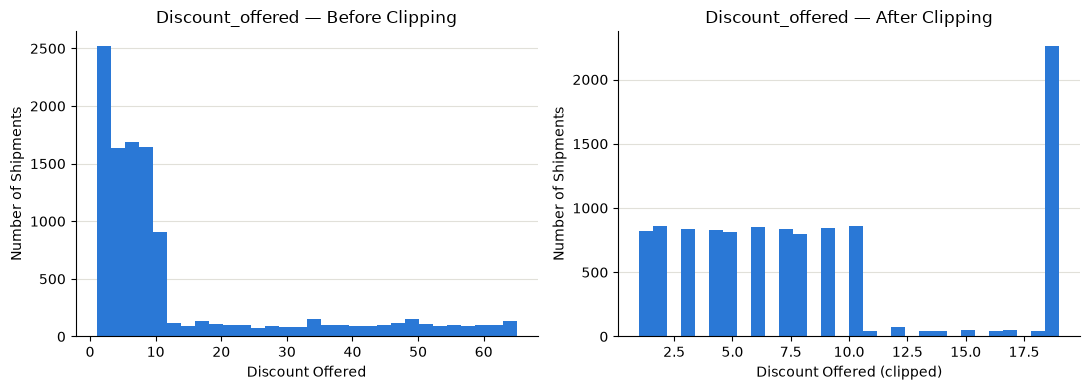

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(demo_clip_df["Discount_offered"], bins=30, color=BAR_COLOR)
axes[0].set_title("Discount_offered — Before Clipping")
axes[0].set_xlabel("Discount Offered")
axes[0].set_ylabel("Number of Shipments")
style_axes(axes[0])

axes[1].hist(demo_clip_df["Discount_offered_clipped"], bins=30, color=BAR_COLOR)
axes[1].set_title("Discount_offered — After Clipping")
axes[1].set_xlabel("Discount Offered (clipped)")
axes[1].set_ylabel("Number of Shipments")
style_axes(axes[1])

plt.tight_layout()
plt.show()


### Critical Rules

- Outlier'lar **otomatik olarak silinmemelidir** — bu LAB'da da silinmemiştir, yalnızca işaretlenmiş
  ve bir kopyada kırpılmıştır.
- Nadir gözlemler, yalnızca istatistiksel olarak "uzak" oldukları için **veri hatası olarak
  tanımlanmamalıdır**.
- Gelecekte bir pipeline'da kullanılacak outlier sınırları (örn. `lower`/`upper`), **yalnızca training
  verisinden** öğrenilmelidir — validation/test değerleriyle yeniden hesaplanmamalıdır (Section 3'teki
  imputer örneğiyle aynı leakage mantığı burada da geçerlidir).
- Outlier treatment yöntemi (silme, kırpma, dönüştürme, veya hiçbir şey yapmama), **iş hedeflerine**
  göre seçilmelidir.

**Bilinçli tasarım kararı:** Bu LAB'da, Section 7'de kuracağımız ana preprocessing pipeline'ına
**outlier clipping dahil edilmeyecektir** — çünkü bu dönüşüm için güçlü bir iş gerekçemiz yok (yukarıdaki
`Discount_offered` çarpıklığının bir hata mı yoksa gerçek bir iş kuralı mı olduğunu bilmiyoruz). Pipeline'a
yalnızca gerekçelendirebildiğimiz dönüşümleri (imputation, encoding, scaling) dahil ediyoruz.

### Student Exercise


In [26]:
# Student Exercise:
# TODO: Compute the IQR bounds for "Customer_care_calls" using the iqr_bounds() function above.
# TODO: Count how many observations fall outside those bounds.

# lower, upper = iqr_bounds(df["Customer_care_calls"])


---
## Section 5 — Categorical Encoding & Feature Scaling
**Süre: 20 dakika**

## Part A — Categorical Encoding

### Learning Objective

Nominal ve ordinal kategorik değişkenler arasındaki farkı anlamak; `OneHotEncoder` ile kategorik
değişkenleri sayısal forma dönüştürmek.

### Concept Explanation

- **Nominal Features**: Kategoriler arasında doğal bir sıralama yoktur (örn. `Mode_of_Shipment`:
  Flight/Road/Ship).
- **Ordinal Features**: Kategoriler arasında doğal bir sıralama vardır (örn. `Product_importance`:
  low < medium < high).
- **One-Hot Encoding**: Her kategori için ayrı bir binary (0/1) sütun oluşturur; sıralama varsaymaz —
  nominal değişkenler için güvenli bir varsayılan seçimdir.
- **Ordinal Encoding**: Her kategoriye, belirlenen sıraya göre tek bir tam sayı atar; sıralamayı
  korur ama One-Hot'tan farklı olarak "büyüklük farkı" ima eder.
- **Unknown Categories**: Encoder'ın `fit` edildiği veride görmediği bir kategoriyle validation/test
  aşamasında karşılaşma durumu.
- **High Cardinality**: Bir kategorik değişkenin çok fazla farklı değer içermesi (One-Hot Encoding'i
  verimsiz hale getirebilir).
- **Encoded Feature Names**: One-Hot Encoding sonrasında her kategori için oluşan yeni sütun isimleri
  (örn. `Gender_F`, `Gender_M`).

### Hands-On


In [27]:
for col in categorical_columns:
    print(f"{col}: {df[col].nunique()} categories -> {sorted(df[col].unique())}")


Warehouse_block: 5 categories -> ['A', 'B', 'C', 'D', 'F']
Mode_of_Shipment: 3 categories -> ['Flight', 'Road', 'Ship']
Product_importance: 3 categories -> ['high', 'low', 'medium']
Gender: 2 categories -> ['F', 'M']


In [28]:
from sklearn.preprocessing import OneHotEncoder

demo_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
demo_encoded = demo_encoder.fit_transform(df[categorical_columns])

encoded_feature_names = demo_encoder.get_feature_names_out(categorical_columns)
print("Encoded feature count:", len(encoded_feature_names))
print("Encoded feature names:", list(encoded_feature_names))


Encoded feature count: 13
Encoded feature names: ['Warehouse_block_A', 'Warehouse_block_B', 'Warehouse_block_C', 'Warehouse_block_D', 'Warehouse_block_F', 'Mode_of_Shipment_Flight', 'Mode_of_Shipment_Road', 'Mode_of_Shipment_Ship', 'Product_importance_high', 'Product_importance_low', 'Product_importance_medium', 'Gender_F', 'Gender_M']


### `handle_unknown="ignore"` Davranışı

Eğer validation veya test verisinde, `fit` sırasında görülmemiş yeni bir kategori ortaya çıkarsa:

- `handle_unknown="error"` (varsayılan) → encoder bir hata (`ValueError`) fırlatır ve pipeline çöker.
- `handle_unknown="ignore"` → o kategori için **tüm one-hot sütunları `0`** olur (hata fırlatılmaz).

Aşağıda, encoder'ı yalnızca birkaç kategoriyle `fit` edip, görmediği bir kategoriyle `transform`
çağırarak bu davranışı gösteriyoruz.


In [29]:
tiny_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
tiny_encoder.fit([["Flight"], ["Road"]])  # "Ship" is intentionally NOT included during fit.

result = tiny_encoder.transform([["Ship"]])
print("Categories seen during fit:", tiny_encoder.categories_)
print("Transform result for the unseen category 'Ship':", result)
print("-> no error raised; the unseen category is encoded as all zeros.")


Categories seen during fit: [array(['Flight', 'Road'], dtype=object)]
Transform result for the unseen category 'Ship': [[0. 0.]]
-> no error raised; the unseen category is encoded as all zeros.


### `Product_importance` — Ordinal Bir İstisna

`Product_importance` (`low`, `medium`, `high`), diğer üç kategorik değişkenden farklı olarak
**ordinal**dır. One-Hot Encoding onu da nominal gibi ele alır (sıralamayı tamamen göz ardı eder); bir
alternatif olarak `OrdinalEncoder` ile açık bir sıra tanımlayabiliriz:


In [30]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder(categories=[["low", "medium", "high"]])
ordinal_encoded = ordinal_encoder.fit_transform(df[["Product_importance"]])

print("Learned category order:", ordinal_encoder.categories_)
pd.Series(ordinal_encoded.ravel()).value_counts().sort_index()


Learned category order: [array(['low', 'medium', 'high'], dtype=object)]


0.0    5297
1.0    4754
2.0     948
Name: count, dtype: int64

Bu LAB'daki ana preprocessing pipeline'ında (Section 7), **basitlik ve güvenlik için tüm dört kategorik
değişkende One-Hot Encoding** kullanılacaktır. `OrdinalEncoder` alternatifi burada sadece kavramsal
farkı göstermek içindir — hangi yaklaşımın seçileceği, kullanılacak modele ve iş bağlamına bağlıdır.

### Important

Kategorilere keyfî sayısal kodlar (örn. `Flight=1, Road=2, Ship=3`) vererek **var olmayan bir büyüklük
ilişkisi** oluşturmayın — bu, nominal bir değişken için yanlış bir varsayımdır ve bazı modellerin
"Road, Flight'tan büyük" gibi anlamsız bir ilişki öğrenmesine yol açabilir.

## Part B — Feature Scaling

### Learning Objective

Farklı ölçeklerdeki sayısal değişkenlerin, `StandardScaler` ve `MinMaxScaler` ile nasıl
karşılaştırılabilir bir ölçeğe getirildiğini görmek.

### Concept Explanation

- **Feature Scaling**: Sayısal değişkenleri, karşılaştırılabilir bir ölçeğe getirme işlemidir.
- **StandardScaler**: Her değeri `(x - mean) / std` formülüyle dönüştürür; sonuç ortalaması `0`,
  standart sapması `1` olan bir dağılımdır.
- **MinMaxScaler**: Her değeri, belirlenen bir aralığa (varsayılan `[0, 1]`) ölçekler.
- **RobustScaler**: Median ve IQR kullanır; outlier'lara karşı daha dayanıklıdır (Section 4'te
  tanıtıldı, `Advanced Challenge 2`'de karşılaştırılacaktır).
- **Scaling Before/After**: Scaling, değişkenin **şeklini (dağılımını) değiştirmez** — yalnızca ölçeğini
  değiştirir.
- **Algorithm Sensitivity**: Decision Tree / Random Forest gibi algoritmalar ölçek farklılıklarından
  etkilenmez (bölme kuralları her feature'ı ayrı ayrı değerlendirir). KNN, SVM ve gradient-based
  yöntemler (örn. Logistic Regression, Neural Networks) ise ölçek farklılıklarından **etkilenir**.

### Hands-On — Gösterim Amaçlı Karşılaştırma

> Aşağıdaki karşılaştırma, yalnızca iki scaler'ın **etkisini görsel/sayısal olarak göstermek** içindir
> ve tüm `df` üzerinde çalışır. Bu, resmi preprocessing pipeline'ımız **değildir** — doğru sıralama
> (önce train/val/test ayrımı, sonra yalnızca train'e `fit`) Section 6 ve 7'de uygulanacaktır.


In [31]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

demo_column = "Weight_in_gms"

standard_scaled = StandardScaler().fit_transform(df[[demo_column]])
minmax_scaled = MinMaxScaler().fit_transform(df[[demo_column]])

comparison = pd.DataFrame(
    {
        "original": df[demo_column].values,
        "standard_scaled": standard_scaled.ravel(),
        "minmax_scaled": minmax_scaled.ravel(),
    }
)
comparison.describe().round(3)


,original,standard_scaled,minmax_scaled
count,10999.000,10999.000,10999.000
mean,3634.017,-0.000,0.385
std,1635.377,1.000,0.239
min,1001.000,-1.610,0.000
25%,1839.500,-1.097,0.122
50%,4149.000,0.315,0.460
75%,5050.000,0.866,0.592
max,7846.000,2.576,1.000


### Educational Explanation

- `StandardScaler`, mean ve standard deviation'ı **öğrenir** (`.mean_`, `.scale_`).
- `MinMaxScaler`, minimum ve maksimum değerleri **öğrenir** (`.data_min_`, `.data_max_`).
- Bu öğrenilen değerler, **yalnızca training verisinden** hesaplanmalıdır (Section 6/7'de bunu
  uygulayacağız).
- Decision Tree gibi algoritmalar her durumda scaling **gerektirmez**.
- KNN, SVM ve gradient-based yöntemler, ölçek farklılıklarından **etkilenebilir** — scaling bu
  algoritmalar için genellikle önemlidir.

### Student Exercise

Aynı numerical feature üzerinde `StandardScaler` ve `MinMaxScaler` sonuçlarını karşılaştırın.


In [32]:
# Student Exercise:
# TODO: Repeat the comparison above for "Cost_of_the_Product" instead of "Weight_in_gms".
# TODO: Comment on whether the two scalers preserve the same relative ordering of values.

# cost_standard = StandardScaler().fit_transform(df[["Cost_of_the_Product"]])
# cost_minmax = MinMaxScaler().fit_transform(df[["Cost_of_the_Product"]])


---
## Section 6 — Train / Validation / Test Split & Data Leakage
**Süre: 20 dakika**

### Learning Objective

Dataset'i leakage'dan arındırılmış şekilde training, validation ve test kümelerine ayırmak; Data
Leakage kavramını somut bir örnekle göstermek.

### Concept Explanation

- **Training Set**: Modelin (ve preprocessing adımlarının) parametrelerini **öğrendiği** veri.
- **Validation Set**: Model/preprocessing kararlarını ayarlamak için kullanılan, eğitimde
  kullanılmayan veri.
- **Test Set**: Nihai performansı değerlendirmek için kullanılan, tamamen "unseen" veri.
- **Random Split vs Stratified Split**: Random split, satırları rastgele ayırır; Stratified split,
  her bölmede hedef sınıf oranlarını orijinal dataset ile aynı tutar.
- **Reproducibility**: Aynı `random_state` ile her çalıştırmada aynı bölmelerin elde edilmesi.
- **Data Leakage**: Model/preprocessing'in, değerlendirme aşamasında "unseen" olması gereken bilgiye
  dolaylı olarak erişmesidir.
- **Preprocessing Leakage**: Bir preprocessing adımının (örn. scaler) parametrelerinin, training
  dışındaki veriden de öğrenilmesi.
- **Target Leakage**: Feature matrisine, hedef değişkenle doğrudan veya dolaylı olarak çok yakından
  ilişkili bir bilginin (örn. hedefin kendisi, ya da hedeften türetilmiş bir alan) karışması.
- **Prediction Time Availability**: Bir feature'ın, gerçek bir tahmin yapılacağı anda gerçekten elde
  olup olmadığıdır (bkz. bu notebook'un başındaki "Önemli bir sınırlama" notu).

### Hands-On — Feature Matrix ve Target


In [33]:
# "ID" is an identifier, not a feature. The target column must not appear in the feature matrix.
feature_columns = [col for col in df.columns if col not in ("ID", "Reached.on.Time_Y.N")]

X = df[feature_columns]
y = df["Reached.on.Time_Y.N"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("'ID' in X.columns:", "ID" in X.columns)
print("'Reached.on.Time_Y.N' in X.columns:", "Reached.on.Time_Y.N" in X.columns)


X shape: (10999, 10)
y shape: (10999,)
'ID' in X.columns: False
'Reached.on.Time_Y.N' in X.columns: False


### Train / Validation / Test Split

Hedeflenen dağılım: **Training %70 / Validation %15 / Test %15**. Hedef sınıf dağılımı aşırı
dengesiz olmadığı için (`~%60 / %40`), `stratify=y` ile **stratified split** uygulayacağız —
bu, her üç bölmede de sınıf oranlarının orijinal dataset ile tutarlı kalmasını sağlar.

Scikit-learn'ün `train_test_split` fonksiyonu doğrudan üçlü bölme yapmaz; bu yüzden **iki aşamalı**
bir bölme uygularız: önce training'i ayırırız, sonra kalanı validation ve test olarak ikiye böleriz.


In [34]:
from sklearn.model_selection import train_test_split

# Step 1: separate the 70% training set from the remaining 30%.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

# Step 2: split the remaining 30% evenly into validation (15%) and test (15%).
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

for name, data in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    print(f"{name:11s}: {data.shape[0]:5d} rows ({data.shape[0] / len(df) * 100:.2f}% of total)")


train      :  7699 rows (70.00% of total)
validation :  1650 rows (15.00% of total)
test       :  1650 rows (15.00% of total)


### Validation Checks


In [35]:
print("Target distribution per split (%):")
for name, target in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    pct = (target.value_counts(normalize=True).sort_index() * 100).round(2)
    print(f"{name:11s}: {pct.to_dict()}")


Target distribution per split (%):
train      : {0: 40.33, 1: 59.67}
validation : {0: 40.3, 1: 59.7}
test       : {0: 40.36, 1: 59.64}


In [36]:
train_val_overlap = set(X_train.index) & set(X_val.index)
train_test_overlap = set(X_train.index) & set(X_test.index)
val_test_overlap = set(X_val.index) & set(X_test.index)

print("Index overlap train/validation:", len(train_val_overlap))
print("Index overlap train/test      :", len(train_test_overlap))
print("Index overlap validation/test :", len(val_test_overlap))
print()
print("random_state used for both split steps:", RANDOM_STATE)
print("Target separated from features in both X_train and X_val/X_test:",
      "Reached.on.Time_Y.N" not in X_train.columns)


Index overlap train/validation: 0
Index overlap train/test      : 0
Index overlap validation/test : 0

random_state used for both split steps: 42
Target separated from features in both X_train and X_val/X_test: True


### Output Interpretation

- Üç bölme de yaklaşık `%70 / %15 / %15` oranındadır ve hedef sınıf dağılımı her bölmede orijinal
  dataset'e (`~%60 Late / %40 On Time`) çok yakındır — stratified split'in beklenen etkisi budur.
- Üç bölme arasında **sıfır index örtüşmesi** vardır — her gözlem tam olarak bir bölmeye aittir.
- Aynı `random_state` (config'den okunan `RANDOM_STATE`) kullanıldığı için bu bölme **tekrar
  üretilebilir**dir.

### Data Leakage Demonstration

**Yanlış yaklaşım** (kavramsal olarak):

```python
# Incorrect: learns scaling parameters from the ENTIRE dataset (train + val + test combined)
scaler.fit_transform(X)
```

**Doğru yaklaşım:**

```python
# Correct: learns scaling parameters only from the training data
scaler.fit(X_train_numeric)

X_train_scaled = scaler.transform(X_train_numeric)
X_val_scaled = scaler.transform(X_val_numeric)
X_test_scaled = scaler.transform(X_test_numeric)
```

> **Not:** Bu örnek yalnızca **sayısal** feature'lar için çalışır. `X_train` hâlâ kategorik (metin)
> sütunlar içerdiği için `StandardScaler`'ı doğrudan ham `X_train` DataFrame'ine uygulayamayız —
> `StandardScaler` yalnızca sayısal girdi bekler ve metin bir sütunla karşılaştığında hata verir. Bu,
> Section 7'de `ColumnTransformer` kullanmamızın tam nedenidir: sayısal ve kategorik sütunları **farklı**
> dönüşümlerden geçirip sonunda birleştirmemiz gerekir.

### Additional Warning

Bu veri kümesinde bir zaman/tarih değişkeni bulunmadığı için burada **random (stratified) split**
kullanmak uygundur. Ancak **Time Series Forecasting** problemlerinde (örn. gelecekteki satışları
tahmin etme), veriyi rastgele bölmek leakage'a yol açar — böyle durumlarda veri **kronolojik olarak**
bölünmelidir (training her zaman validation/test'ten zaman açısından önce gelmelidir).

### Critical Rule

Model geliştirme veya değerlendirme sürecinin **hiçbir aşamasında**, test verisi preprocessing
parametrelerini öğrenmek için kullanılmamalıdır.

### Student Exercise


In [37]:
# Student Exercise:
# TODO: Confirm (again, in your own words via print statements) that X_train, X_val, and X_test
#       contain no "ID" or "Reached.on.Time_Y.N" columns.
# TODO: Confirm that X_train.shape[0] + X_val.shape[0] + X_test.shape[0] == len(df).

# print(X_train.shape[0] + X_val.shape[0] + X_test.shape[0] == len(df))


---
## Section 7 — Scikit-learn Pipeline & ColumnTransformer
**Süre: 25 dakika**

**Bu LAB'ın en önemli bölümüdür.**

### Learning Objective

Numerical ve categorical feature'ları farklı işlemlerden geçiren, leakage'dan arındırılmış, tek bir
preprocessing pipeline'ı inşa etmek.

### Concept Explanation

- **Why Pipelines Matter**: Bir `Pipeline`, birden fazla dönüşüm adımını **tek bir nesnede** zincirler;
  her adımın training verisine `fit` edilip, diğer tüm verilere aynı sırayla `transform` edilmesini
  garanti eder — adımları unutmak veya yanlış sırada uygulamak neredeyse imkansız hale gelir.
- **Reusable Transformations**: Bir kez kurulan pipeline, hem validation/test verisine hem de (ileride)
  gerçek dünya verisine aynı şekilde uygulanabilir.
- **`ColumnTransformer`**: Farklı sütun gruplarına (örn. numerical vs categorical) **farklı**
  pipeline'lar uygulamayı ve sonucu tek bir çıktıda birleştirmeyi sağlar.
- **`fit` vs `transform` vs `fit_transform`**: `fit`, parametreleri öğrenir (hiçbir veri döndürmez);
  `transform`, zaten öğrenilmiş parametrelerle veriyi dönüştürür; `fit_transform`, ikisini art arda
  yapan bir kısayoldur — **yalnızca training verisinde** kullanılmalıdır.
- **Feature Names**: `ColumnTransformer.get_feature_names_out()`, dönüştürülmüş çıktıdaki her sütunun
  hangi orijinal feature'dan geldiğini izlemeyi sağlar.
- **Data Leakage Prevention / Reproducibility**: Pipeline, `fit`'in yalnızca bir kez (training verisiyle)
  çağrılmasını sağlayarak bu LAB boyunca vurguladığımız leakage kuralını **kod seviyesinde** garanti
  eder.

### Part A — Numerical Pipeline

İki adım: eksik değer doldurma (median — Section 3'te gördüğümüz gibi robust bir seçimdir), ardından
scaling.


In [38]:
from sklearn.pipeline import Pipeline

numerical_features = [
    "Customer_care_calls",
    "Customer_rating",
    "Cost_of_the_Product",
    "Prior_purchases",
    "Discount_offered",
    "Weight_in_gms",
]

numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
numerical_pipeline


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account fo

### Part B — Categorical Pipeline

İki adım: eksik değer doldurma (most_frequent — kategorik veri için anlamlı bir strateji), ardından
One-Hot Encoding.


In [39]:
categorical_features = [
    "Warehouse_block",
    "Mode_of_Shipment",
    "Product_importance",
    "Gender",
]

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)
categorical_pipeline


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('encoder', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto ac

> **`sparse_output=False` notu:** `OneHotEncoder`, varsayılan olarak bellek açısından verimli bir
> **sparse** matris üretir — bu, özellikle çok fazla kategorisi olan (high cardinality) değişkenler
> için önemlidir. Bu LAB'daki dört kategorik değişkenin kardinalitesi düşük olduğu için (toplam 13
> one-hot sütunu), `sparse_output=False` ile **dense** (ve okunabilir bir DataFrame olarak
> görüntülenebilir) çıktı üretmek burada güvenlidir. Çok daha fazla kategorisi olan bir değişken için
> bu seçim yeniden değerlendirilmelidir.

### Part C — ColumnTransformer

Numerical ve categorical pipeline'ları, ilgili sütun listeleriyle birleştiriyoruz.


In [40]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    verbose_feature_names_out=False,
)
preprocessor


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per tr

### Part D — Complete Preprocessing Pipeline

`ColumnTransformer`'ı, dışarıdan tek bir adım olarak kullanılabilecek genel bir `Pipeline` içine
yerleştiriyoruz. Bu LAB'da pipeline'ın sonuna **herhangi bir Machine Learning estimator'ı
eklenmemektedir** — amaç yalnızca preprocessing'tir. LAB05/LAB06'da, bu pipeline'ın sonuna bir model
adımı eklenerek (örn. `("model", LogisticRegression())`) genişletilecektir.


In [41]:
preprocessing_pipeline = Pipeline(steps=[("preprocessing", preprocessor)])
preprocessing_pipeline


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}

### Pipeline Execution

Sıra: (1) training verisi zaten Section 6'da hazır (`X_train`), (2) pipeline yukarıda kuruldu,
(3) pipeline'ı training verisine `fit` et, (4) training verisini `transform` et, (5) validation
verisini `transform` et, (6) test verisini `transform` et.

`set_config(transform_output="pandas")`, dönüştürülmüş çıktının bir NumPy array yerine, sütun adlarını
koruyan okunabilir bir Pandas `DataFrame` olarak dönmesini sağlar.


In [42]:
from sklearn import set_config

set_config(transform_output="pandas")

# fit_transform() on training data ONLY: this is where every statistic (median, mean, std,
# most-frequent category, one-hot category list) is learned.
X_train_transformed = preprocessing_pipeline.fit_transform(X_train)

# transform() on validation/test: reuses the parameters learned above, learns nothing new.
X_val_transformed = preprocessing_pipeline.transform(X_val)
X_test_transformed = preprocessing_pipeline.transform(X_test)

print("X_train_transformed shape:", X_train_transformed.shape)
print("X_val_transformed shape  :", X_val_transformed.shape)
print("X_test_transformed shape :", X_test_transformed.shape)


X_train_transformed shape: (7699, 19)
X_val_transformed shape  : (1650, 19)
X_test_transformed shape : (1650, 19)


### Critical Validation


In [43]:
transformed_feature_names = preprocessor.get_feature_names_out()
print("Transformed feature count:", len(transformed_feature_names))
print("Transformed feature names:", list(transformed_feature_names))


Transformed feature count: 19
Transformed feature names: ['Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms', 'Warehouse_block_A', 'Warehouse_block_B', 'Warehouse_block_C', 'Warehouse_block_D', 'Warehouse_block_F', 'Mode_of_Shipment_Flight', 'Mode_of_Shipment_Road', 'Mode_of_Shipment_Ship', 'Product_importance_high', 'Product_importance_low', 'Product_importance_medium', 'Gender_F', 'Gender_M']


In [44]:
X_train_transformed.head()


,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms,Warehouse_block_A,Warehouse_block_B,Warehouse_block_C,Warehouse_block_D,Warehouse_block_F,Mode_of_Shipment_Flight,Mode_of_Shipment_Road,Mode_of_Shipment_Ship,Product_importance_high,Product_importance_low,Product_importance_medium,Gender_F,Gender_M
9578,-0.922596,-1.407946,0.543442,-0.377583,-0.333852,1.047834,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
2356,-0.922596,1.417303,1.127634,-1.033942,1.211521,-0.989631,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
3782,-0.041103,-1.407946,-1.104813,-1.033942,-0.519297,1.235624,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
5847,0.840389,1.417303,-0.541486,-0.377583,-0.395667,0.680231,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
6134,-0.922596,0.004679,-1.063085,-0.377583,-0.642927,0.979714,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0


In [45]:
# Encoded categorical columns: each is a 0/1 indicator.
encoded_sample_columns = [c for c in X_train_transformed.columns if c.startswith(("Gender_", "Product_importance_"))]
X_train_transformed[encoded_sample_columns].head()


,Product_importance_high,Product_importance_low,Product_importance_medium,Gender_F,Gender_M
9578,0.0,0.0,1.0,1.0,0.0
2356,0.0,0.0,1.0,0.0,1.0
3782,0.0,0.0,1.0,1.0,0.0
5847,0.0,0.0,1.0,0.0,1.0
6134,0.0,1.0,0.0,0.0,1.0


In [46]:
# Scaled numerical columns: on the TRAINING set, mean should be ~0 and std should be ~1,
# because the scaler's parameters were learned directly from this data.
X_train_transformed[numerical_features].agg(["mean", "std"]).round(3)


,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms
mean,0.0,-0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


In [47]:
# On the VALIDATION set, mean/std will NOT be exactly 0/1 -- this is expected and is itself a
# leakage check: if the scaler had been re-fit on X_val, its mean would again be ~0.
# Since it is close to (but not exactly) 0/1, we confirm the scaler reused the TRAINING parameters.
X_val_transformed[numerical_features].agg(["mean", "std"]).round(3)


,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Discount_offered,Weight_in_gms
mean,0.034,-0.007,0.016,-0.013,-0.024,0.009
std,1.029,0.988,1.018,1.003,0.990,1.011


In [48]:
fitted_scaler = preprocessing_pipeline.named_steps["preprocessing"].named_transformers_["numerical"].named_steps["scaler"]

print("Learned mean_ (from X_train only):")
print(pd.Series(fitted_scaler.mean_, index=numerical_features).round(3))
print()
print("These learned parameters do not change when transforming X_val or X_test --")
print("the scaler was fit exactly once, on X_train.")


Learned mean_ (from X_train only):
Customer_care_calls       4.047
Customer_rating           2.993
Cost_of_the_Product     209.953
Prior_purchases           3.575
Discount_offered         13.401
Weight_in_gms          3633.580
dtype: float64

These learned parameters do not change when transforming X_val or X_test --
the scaler was fit exactly once, on X_train.


### Reusability

Bu preprocessing pipeline'ı (`preprocessing_pipeline`), sonraki **LAB05** ve **LAB06** çalışmalarında,
sonuna bir `estimator` adımı eklenerek (örn. `preprocessing_pipeline.steps.append(("model", ...))`)
doğrudan yeniden kullanılabilir. Bu LAB kapsamında herhangi bir model eğitilmemektedir.

### Student Exercise


In [49]:
# Student Exercise:
# TODO: Inspect the categories learned by the OneHotEncoder for "Warehouse_block".
# TODO: Confirm the count of learned categories matches df["Warehouse_block"].nunique().

# fitted_encoder = preprocessing_pipeline.named_steps["preprocessing"].named_transformers_["categorical"].named_steps["encoder"]
# print(fitted_encoder.categories_)


---
## Section 8 — Preprocessing Validation & Workshop
**Süre: 15 dakika**

### Workshop Objective

Bu bölümde, veri hazırlama sürecinin doğru çalıştığını **kendi başınıza** doğrulayacaksınız.

### Student Tasks

1. Numerical ve Categorical Features listelerini oluşturun.
2. Target Variable'ı ayırın.
3. Train/Validation/Test Split gerçekleştirin.
4. Numerical Pipeline oluşturun.
5. Categorical Pipeline oluşturun.
6. `ColumnTransformer` ile birleştirin.
7. Pipeline'ı training verisine `fit` edin.
8. Validation ve test verilerini dönüştürün.
9. Transform edilmiş feature sayısını inceleyin.
10. Data Leakage oluşmadığını destekleyen kontrolleri gerçekleştirin.


In [50]:
# Workshop Scaffold — Fill in each TODO using the techniques from Sections 5-7. This cell is
# intentionally left as a template so it does not block sequential notebook execution.

# TODO 1-2. Feature lists and target (reuse numerical_features, categorical_features, X, y above,
#           or redefine them here from scratch as practice).

# TODO 3. Train/Validation/Test split
# X_train2, X_temp2, y_train2, y_temp2 = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
# X_val2, X_test2, y_val2, y_test2 = train_test_split(X_temp2, y_temp2, test_size=0.50, stratify=y_temp2, random_state=RANDOM_STATE)

# TODO 4-6. Build numerical_pipeline, categorical_pipeline, and combine into a ColumnTransformer.

# TODO 7-8. Fit on training data only, then transform validation and test data.

# TODO 9. Inspect the transformed feature count via get_feature_names_out().

# TODO 10. Verify no leakage: compare learned scaler.mean_ against X_train2 means directly.


### Expected Results

- Reusable Preprocessing Pipeline
- Correct Data Splitting
- Consistent Feature Transformation
- No Unintended Target Leakage
- Reproducible Execution
- Readable Validation Outputs

### Critical Discussion

**"Yeni bir kategorik değer validation veya test verisinde ortaya çıkarsa ne olur?"**

Section 5'te gösterdiğimiz gibi, `OneHotEncoder(handle_unknown="ignore")` bu durumda hata fırlatmaz —
o gözlem için ilgili kategorik değişkenin tüm one-hot sütunları `0` olarak encode edilir. Model, bu
gözlemi "bilinen kategorilerden hiçbiri değil" olarak görür; veri tamamen kaybolmaz ama o değişkene
özgü bilgi o gözlem için kullanılamaz. `handle_unknown="error"` (varsayılan davranış) kullanılsaydı,
pipeline bu noktada çökerdi.

**"Bir modelin eğitim ve test verilerine farklı scaler fit edilirse neden problem oluşur?"**

Eğer training verisine bir `StandardScaler` (`mean_train`, `std_train`), test verisine de **ayrıca**
`fit` edilen başka bir `StandardScaler` (`mean_test`, `std_test`) uygulanırsa, aynı ham değer, hangi
sette olduğuna bağlı olarak **farklı** bir ölçeklenmiş değere dönüşür. Model, training sırasında
`mean_train`/`std_train`'e göre tanımlanmış bir sayısal uzayda öğrenim yapmıştır; test verisi
`mean_test`/`std_test`'e göre dönüştürülürse, model artık **tutarsız bir girdi uzayında**
değerlendirilir — bu, performans sonuçlarını anlamsız hale getirebilir. Bu yüzden Section 6-7'de
sürekli vurguladığımız kural geçerlidir: scaler'ın öğrenilen parametreleri **yalnızca training
verisinden** gelmeli, validation ve test verisine yalnızca `transform` ile (aynı parametrelerle)
uygulanmalıdır.


---
## Advanced Challenges (opsiyonel — ana 150 dakikalık süreye dahil değildir)

Aşağıdaki üç challenge, deneyimli katılımcılar için hazırlanmıştır. Tamamlanmamış olmaları, notebook'un
sıralı çalışmasını etkilemez (tüm hücreler yalnızca yorum satırı içerir).

### Challenge 1 — Custom Transformer

Scikit-learn uyumlu, minimal bir custom transformer oluşturun (`BaseEstimator` ve `TransformerMixin`'den
türetilen, gereksiz inheritance katmanı olmayan basit bir sınıf) — örneğin, Section 4'teki IQR tabanlı
clipping mantığını bir transformer'a dönüştürün.


In [51]:
# Advanced Challenge 1 — Custom Transformer (optional):
# TODO: Create a minimal scikit-learn-compatible transformer that clips a numerical column to its
#       IQR-based [lower, upper] bounds, learned during fit() and reused during transform().

# from sklearn.base import BaseEstimator, TransformerMixin
#
# class IQRClipper(BaseEstimator, TransformerMixin):
#     def __init__(self, factor: float = 1.5):
#         self.factor = factor
#
#     def fit(self, X, y=None):
#         q1, q3 = X.quantile(0.25), X.quantile(0.75)
#         iqr = q3 - q1
#         self.lower_ = q1 - self.factor * iqr
#         self.upper_ = q3 + self.factor * iqr
#         return self
#
#     def transform(self, X):
#         return X.clip(lower=self.lower_, upper=self.upper_, axis=1)


### Challenge 2 — Feature Transformation Comparison

`StandardScaler`, `MinMaxScaler` ve `RobustScaler`'ı, farklı şekillerdeki iki dağılım üzerinde
(`Weight_in_gms` — simetriğe yakın, `Discount_offered` — sağa çarpık) karşılaştırın.


In [52]:
# Advanced Challenge 2 — Feature Transformation Comparison (optional):
# TODO: Fit StandardScaler, MinMaxScaler, and RobustScaler separately on "Weight_in_gms".
# TODO: Repeat for "Discount_offered".
# TODO: Compare the resulting distributions (describe() or histograms) across all three scalers
#       for each variable, and comment on which scaler seems least affected by the skew in
#       "Discount_offered".

# from sklearn.preprocessing import RobustScaler
# robust_scaled = RobustScaler().fit_transform(df[["Discount_offered"]])


### Challenge 3 — Leakage Investigation

Kontrollü bir preprocessing leakage senaryosu oluşturun: `StandardScaler`'ı **tüm** `X_train[numerical_features]`
+ `X_val[numerical_features]` birleşimine `fit` edin (yanlış yaklaşım) ve öğrenilen `mean_` değerlerini,
Section 7'deki doğru pipeline'ın (`fitted_scaler.mean_`, yalnızca `X_train`'e fit edilmiş) öğrendiği
değerlerle karşılaştırın.


In [53]:
# Advanced Challenge 3 — Leakage Investigation (optional):
# TODO: Fit a NEW StandardScaler on pd.concat([X_train[numerical_features], X_val[numerical_features]]).
# TODO: Compare its .mean_ against fitted_scaler.mean_ (the correctly-fit, train-only scaler from Section 7).
# TODO: Comment on why these two sets of learned parameters differ, and why that difference matters.

# leaky_scaler = StandardScaler().fit(pd.concat([X_train[numerical_features], X_val[numerical_features]]))
# print(leaky_scaler.mean_)
# print(fitted_scaler.mean_)


---
## LAB04 Özeti

Bu LAB'da, LAB02 ve LAB03'te öğrendiğiniz bilgileri kullanarak:

- Veri kalitesini sistematik olarak doğruladık ve bir Data Quality Summary oluşturduk.
- Eksik değer mekanizmalarını ve `SimpleImputer` stratejilerini (mean, median, most_frequent, constant)
  öğretim amaçlı, bellekteki bir kopyada gösterdik; duplicate kayıtları tespit edip nasıl ele
  alınabileceğini tartıştık.
- IQR yöntemiyle outlier'ları belirledik, bir kopya üzerinde clipping gösterdik ve ana pipeline'a
  dahil etmeme kararını gerekçelendirdik.
- `OneHotEncoder` ile kategorik değişkenleri encode ettik, `handle_unknown="ignore"` davranışını ve
  ordinal/nominal ayrımını gösterdik.
- `StandardScaler` ve `MinMaxScaler`'ı karşılaştırdık.
- Dataset'i stratified olarak training/validation/test kümelerine ayırdık ve leakage riskini kontrol
  ettik.
- `Pipeline` ve `ColumnTransformer` kullanarak, **yalnızca training verisinden öğrenen**, tekrar
  üretilebilir bir preprocessing pipeline'ı inşa ettik ve bunu somut kontrollerle doğruladık.

Bu preprocessing pipeline'ı, bir sonraki modülde (**LAB05**) bir Machine Learning modeliyle
birleştirilecektir. Bu LAB'da herhangi bir model eğitilmemiştir.

Bir sonraki oturumda görüşmek üzere!
